# Exploratory Data Analysis

This notebook digs into the cleaned dataset from `02_Data_Wrangling.ipynb` to answer the questions the rest of the project (and the dashboard) is built around: what do developers actually use, how satisfied are they, how does remote work vary, and what shapes compensation.

Charts here are exploratory — built to understand the data, not to present it. Polished, presentation-ready versions of the headline findings are in `04_Data_Visualization.ipynb`.

Sections:
1. Job satisfaction
2. Remote work patterns
3. Programming languages: used vs desired
4. Compensation, outliers, and a data-quality catch
5. Correlations between experience, age, compensation, and satisfaction


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("./data/processed/survey_data_clean.csv")
df.shape

(65437, 127)

One more piece of prep before the analysis: `Employment` is still a multi-select string, which is awkward to group by directly. A simple mapping collapses it into single categories:

In [3]:
def simplify_employment(x):
    if pd.isna(x):
        return "Unknown"
    x = str(x).lower()
    if "employed, full-time" in x and "independent contractor" not in x:
        return "Full-time"
    elif "independent contractor" in x or "freelancer" in x or "self-employed" in x:
        return "Freelancer / Self-employed"
    elif "employed, part-time" in x:
        return "Part-time"
    elif "student" in x:
        return "Student"
    elif "not employed, but looking" in x:
        return "Unemployed (looking)"
    elif "not employed, and not looking" in x:
        return "Not employed (not looking)"
    elif "retired" in x:
        return "Retired"
    else:
        return "Other"

df["Employment_simple"] = df["Employment"].apply(simplify_employment)
df["Employment_simple"].value_counts()

Employment_simple
Full-time                     41119
Freelancer / Self-employed    10726
Student                        6482
Part-time                      3003
Unemployed (looking)           2386
Not employed (not looking)      650
Other                           546
Retired                         525
Name: count, dtype: int64

In [4]:
df["Employment_simple"].value_counts(normalize=True).mul(100).round(2).astype(str) + '%'

Employment_simple
Full-time                     62.84%
Freelancer / Self-employed    16.39%
Student                        9.91%
Part-time                      4.59%
Unemployed (looking)           3.65%
Not employed (not looking)     0.99%
Other                          0.83%
Retired                         0.8%
Name: proportion, dtype: str

Unsurprisingly dominated by full-time employees (63%), with freelancers/self-employed as the next largest group (16%).

## 1. Job satisfaction

In [5]:
df["JobSat"].value_counts().sort_index()

JobSat
0.0      311
1.0      276
2.0      772
3.0     1165
4.0     1130
5.0     1956
6.0     3751
7.0     6379
8.0     7509
9.0     3626
10.0    2251
Name: count, dtype: int64

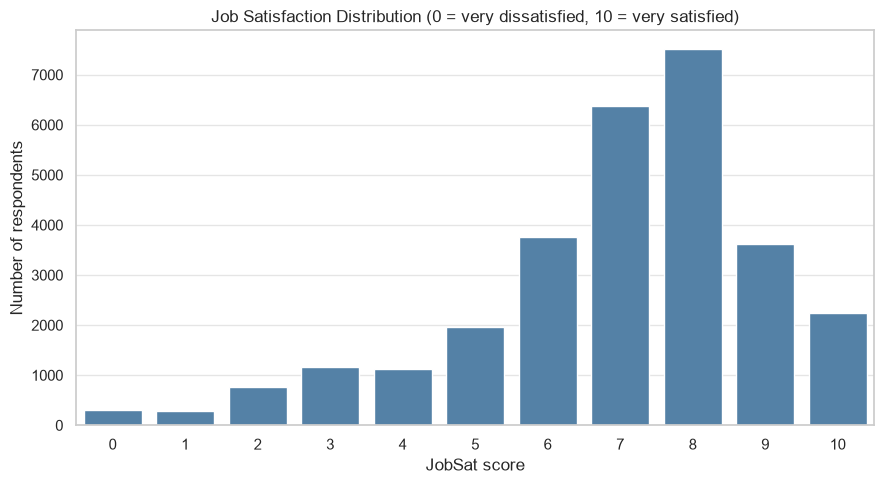

In [6]:
plt.figure(figsize=(9, 5))
sns.barplot(
    x=df["JobSat"].value_counts().sort_index().index.astype(int).astype(str),
    y=df["JobSat"].value_counts().sort_index().values,
    color="steelblue",
    errorbar=None
)
plt.title("Job Satisfaction Distribution (0 = very dissatisfied, 10 = very satisfied)")
plt.xlabel("JobSat score")
plt.ylabel("Number of respondents")
plt.tight_layout()
plt.show()

Left-skewed and clustered at 7–8: most people who answer this question are reasonably to very satisfied with their job. Only about 8% of respondents (JobSat ≤ 3) report real dissatisfaction. (29,126 of the 65,437 respondents answered this question — the rest is structural missingness handled in the wrangling notebook, not re-imputed here.)

How does that relate to experience? A Pearson/Spearman correlation against professional coding experience gives a first read:

In [7]:
years_num = df["YearsCodePro"]
pearson = df["JobSat"].corr(years_num, method="pearson")
spearman = df["JobSat"].corr(years_num, method="spearman")
print(f"Pearson correlation:  {pearson:.4f}")
print(f"Spearman correlation: {spearman:.4f}")

Pearson correlation:  0.1034
Spearman correlation: 0.1207


Positive, but extremely weak — more experienced developers report *slightly* higher job satisfaction, but experience alone explains very little of the variation. Whatever drives satisfaction here, it isn't mainly tenure.

## 2. Remote work patterns

In [8]:
df["RemoteWork"].value_counts()

RemoteWork
Hybrid (some remote, some in-person)    33646
Remote                                  20831
In-person                               10960
Name: count, dtype: int64

Hybrid is the plurality format — though note a third of that number is the mode-imputed missing values from the wrangling stage, so treat the exact split with a little caution; the *ranking* (Hybrid > Remote > In-person) held before imputation too.

Breaking it down by employment type is more informative — and worth a data-quality note. Employment categories like `Retired`, `Student`, or `Not employed (not looking)` show up as **100% Hybrid** in a raw crosstab. That's not a real finding: RemoteWork was essentially unanswered for those groups before imputation, so the mode-fill mechanically assigns all of them to "Hybrid." Restricting to the three groups where the question was actually meaningful and mostly answered avoids that trap:

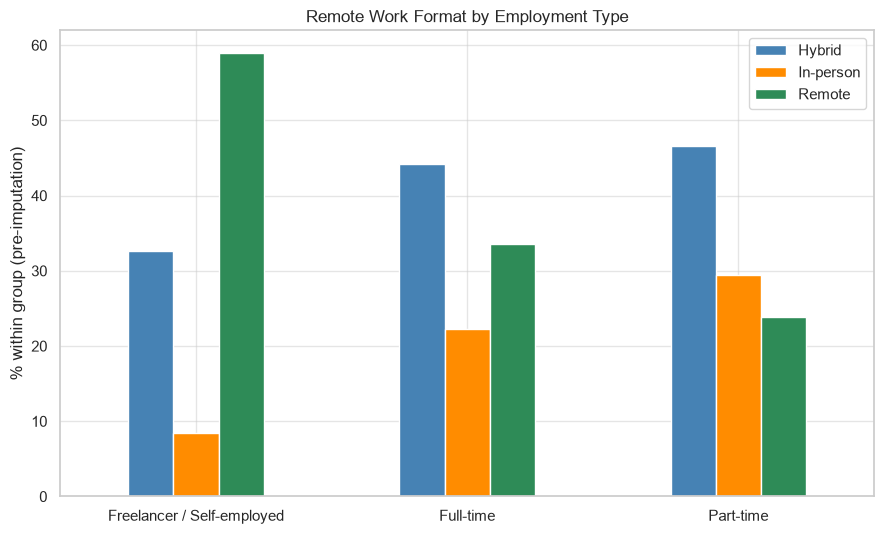

In [10]:
plt.figure(figsize=(9, 5.5))
groups = ["Freelancer / Self-employed", "Full-time", "Part-time"]
shares = pd.DataFrame({
    "Hybrid":    [32.6, 44.2, 46.6],
    "In-person": [8.4, 22.3, 29.4],
    "Remote":    [59.0, 33.5, 23.9],
}, index=groups)
shares.plot(kind="bar", color=["steelblue", "darkorange", "seagreen"], ax=plt.gca())
plt.ylabel("% within group (pre-imputation)")
plt.title("Remote Work Format by Employment Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Freelancers work remote by a wide margin (59%) — which makes sense, that flexibility is a big part of the appeal of freelancing. Full-time employees split closer to evenly across all three formats, and part-timers lean slightly more in-person than full-timers do.

## 3. Programming languages: used vs. desired

In [11]:
have = (df["LanguageHaveWorkedWith"].dropna().str.split(";").explode().str.strip().value_counts())
want = (df["LanguageWantToWorkWith"].dropna().str.split(";").explode().str.strip().value_counts())

lang_compare = pd.concat([have.rename("Have Worked With"), want.rename("Want To Work With")], axis=1)
top_langs = lang_compare.sum(axis=1).sort_values(ascending=False).head(9).index
lang_compare.loc[top_langs]

,Have Worked With,Want To Work With
JavaScript,37492,23774
Python,30719,25047
SQL,30682,22400
HTML/CSS,31816,20721
TypeScript,23150,20239
Bash/Shell (all shells),20412,13744
C#,16318,12921
Java,18239,10668
Rust,7559,17232


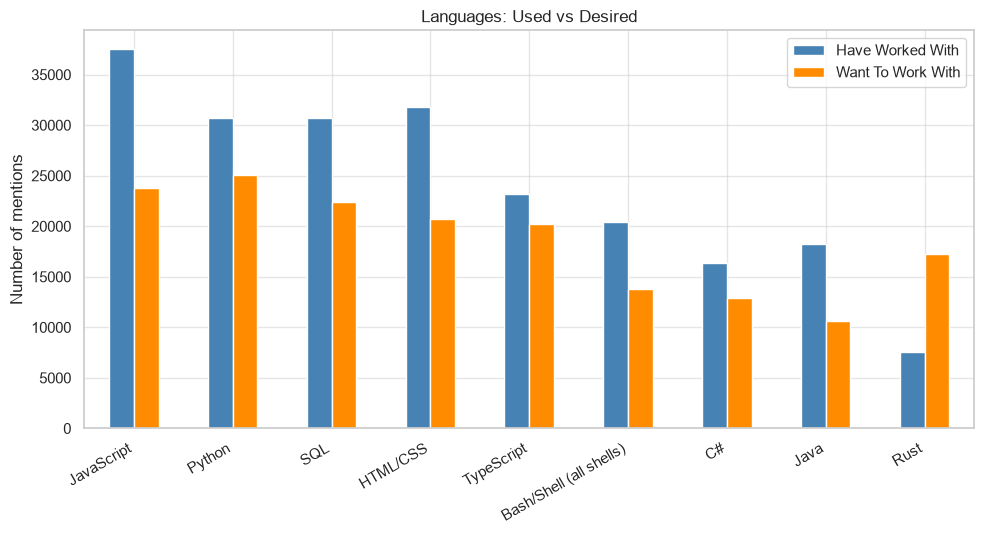

In [12]:
lang_compare.loc[top_langs].plot(kind="bar", figsize=(10, 5.5), color=["steelblue", "darkorange"])
plt.ylabel("Number of mentions")
plt.title("Languages: Used vs Desired")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

JavaScript, Python, and SQL lead both lists — they're the tools people already use *and* the ones they'd keep choosing. The more interesting signal is outside this top 9: **Rust** shows up with only 7,559 "have worked with" mentions but 17,232 "want to work with" — more than double. That gap (desired far more than it's currently used) doesn't show up for any of the established top languages, and it's the kind of forward-looking signal that's easy to miss if you only look at current usage. Worth a closer look in the visualization stage.

## 4. Compensation, outliers, and a data-quality catch

In [15]:
df["Industry"].value_counts().head(12)

Industry
Software Development                          11918
Other:                                         3077
Fintech                                        1641
Internet, Telecomm or Information Services     1629
Banking/Financial Services                     1371
Healthcare                                     1277
Manufacturing                                  1265
Retail and Consumer Services                   1264
Government                                      962
Media & Advertising Services                    894
Higher Education                                890
Transportation, or Supply Chain                 859
Name: count, dtype: int64

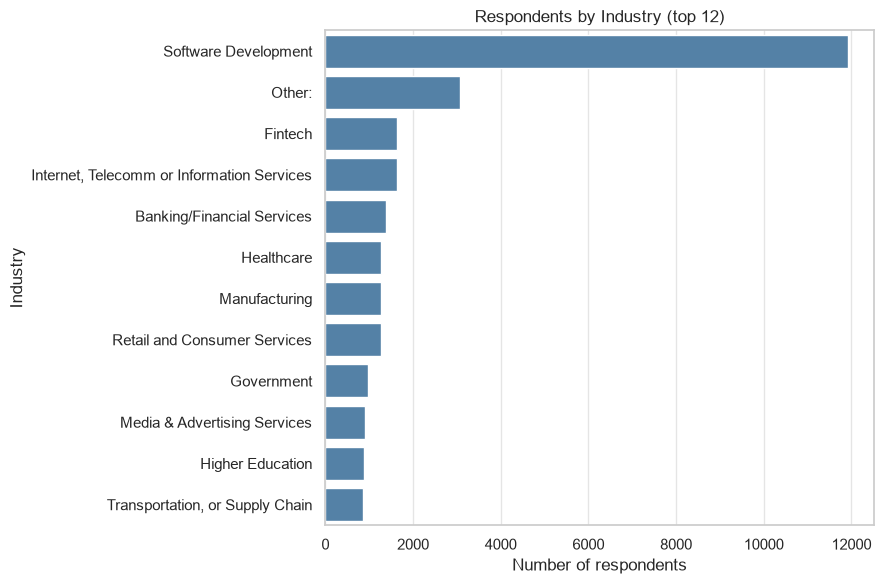

In [16]:
plt.figure(figsize=(9, 6))
sns.barplot(x=df["Industry"].value_counts().head(12).values,
            y=df["Industry"].value_counts().head(12).index, color="steelblue")
plt.title("Respondents by Industry (top 12)")
plt.xlabel("Number of respondents")
plt.tight_layout()
plt.show()

Software Development dominates, as expected for a developer survey — the rest of the mentions are spread thin across a long tail of industries developers work *in* rather than *for*.

### Two ways of finding outliers

In [17]:
comp = df["ConvertedCompYearly"]
comp_mean, comp_median, comp_std = comp.mean(), comp.median(), comp.std()
print(f"Mean:   {comp_mean:,.0f}")
print(f"Median: {comp_median:,.0f}")
print(f"Std:    {comp_std:,.0f}")

threshold_3sigma = comp_mean + 3 * comp_std
high_comp = comp[comp > threshold_3sigma]
print(f"\n3-sigma threshold: {threshold_3sigma:,.0f}")
print(f"Respondents above it: {len(high_comp)} ({len(high_comp) / comp.notna().sum() * 100:.2f}%)")
print(f"Highest value in the data: {comp.max():,.0f}")

Mean:   86,155
Median: 65,000
Std:    186,757

3-sigma threshold: 646,426
Respondents above it: 89 (0.38%)
Highest value in the data: 16,256,603


In [18]:
Q1, Q3 = comp.quantile(0.25), comp.quantile(0.75)
IQR = Q3 - Q1
lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
iqr_outliers = comp[(comp < lower_bound) | (comp > upper_bound)]

print(f"Q1: {Q1:,.0f}  Q3: {Q3:,.0f}  IQR: {IQR:,.0f}")
print(f"Bounds: [{lower_bound:,.0f}, {upper_bound:,.0f}]")
print(f"Flagged as outliers: {len(iqr_outliers)} ({len(iqr_outliers) / comp.notna().sum() * 100:.1f}%)")

Q1: 32,712  Q3: 107,972  IQR: 75,260
Bounds: [-80,177, 220,861]
Flagged as outliers: 978 (4.2%)


The two methods disagree a lot, and that's worth sitting with rather than picking one arbitrarily. 3-sigma flags only 89 respondents (0.4%) — essentially just the absurd values (someone reporting $16M/year is almost certainly a data entry error, not a real salary). IQR flags 978 (4.2%) — but a lot of those are just senior engineers in high-cost-of-living markets earning genuinely high (if unusual) salaries, not errors. **Neither threshold gets used to silently drop rows here** — IQR is too aggressive for a right-skewed variable like compensation, and 3-sigma is more defensible but still blunt. The approach instead: keep the full range for aggregate stats (mean/median), but sanity-check anything that looks extreme by hand — which is exactly how the next issue turned up.

### A $2,000,000 salary in Gabon

Country-level compensation comparisons are an obvious next step, but a quick per-country sanity check caught something before that analysis went any further:

In [19]:
gabon = df[df["Country"] == "Gabon"]
print("Respondents from Gabon:", len(gabon))
gabon[["Country", "ConvertedCompYearly", "Employment", "YearsCodePro", "EdLevel"]]

Respondents from Gabon: 4


,Country,ConvertedCompYearly,Employment,YearsCodePro,EdLevel
2187,Gabon,2000000.0,"Employed, full-time",13.0,Bachelor's
9493,Gabon,NaN,"Not employed, and not looking for work",8.0,Master's
27000,Gabon,NaN,"Student, full-time",NaN,Bachelor's
27646,Gabon,NaN,Retired,NaN,Professional


Four respondents total from Gabon, and the only one with a compensation figure reports **$2,000,000/year**. That's not plausible for any country, let alone one where it would be a wild outlier by local cost of living — almost certainly a data entry error (extra zeros, or a joke response). With a sample size of one, this single value would single-handedly determine "Gabon's" spot in any country ranking, so it gets excluded from country-level compensation comparisons rather than either being trusted at face value or silently averaged in.

In [20]:
country_comp = (
    df[~((df["Country"] == "Gabon") & (df["ConvertedCompYearly"] == 2_000_000))]
    .groupby("Country")["ConvertedCompYearly"]
    .median()
    .dropna()
    .sort_values(ascending=False)
)
country_comp.head(15)

Country
USA                    143000.0
Antigua and Barbuda    126120.0
Andorra                123517.0
Israel                 113334.0
Switzerland            111417.0
Singapore              103482.0
Luxembourg              96288.0
Australia               95465.5
Ireland                 91295.0
Haiti                   90000.0
Denmark                 89137.0
Canada                  87231.0
Samoa                   85620.0
UK                      84076.0
Isle of Man             82802.0
Name: ConvertedCompYearly, dtype: float64

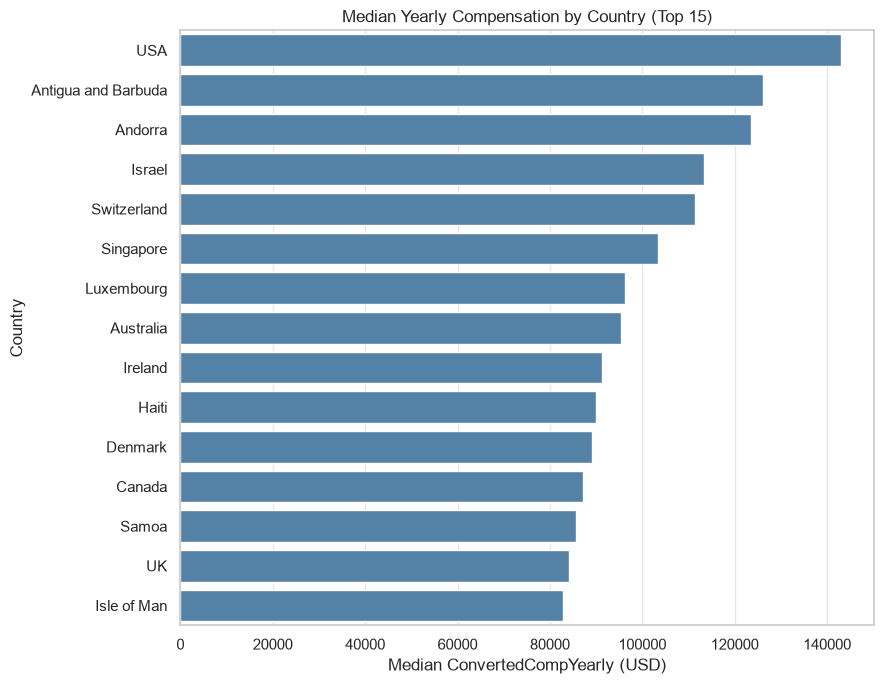

In [21]:
plt.figure(figsize=(9, 7))
top15 = country_comp.head(15)
sns.barplot(x=top15.values, y=top15.index, color="steelblue")
plt.title("Median Yearly Compensation by Country (Top 15)")
plt.xlabel("Median ConvertedCompYearly (USD)")
plt.tight_layout()
plt.show()

USA and Switzerland aside, several names here — Antigua and Barbuda, Andorra, Samoa, Isle of Man — are small enough that a handful of respondents can swing the median. Worth reading this chart as "countries with high *reported* medians," not a reliable national pay ranking, until it's cross-checked against respondent counts per country.

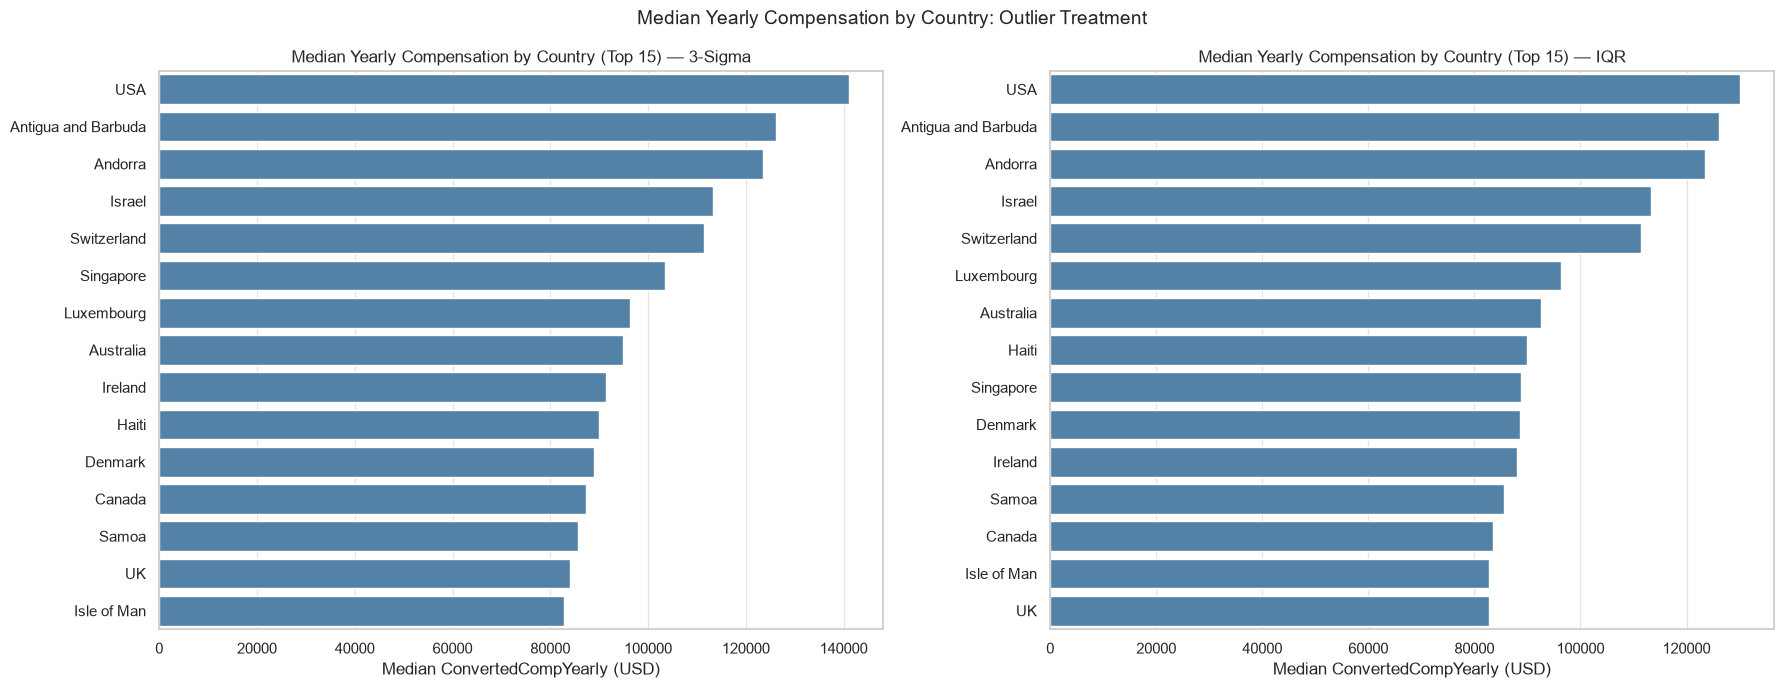

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 3-Sigma
sns.barplot(
    x=top15_3sigma.values,
    y=top15_3sigma.index,
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Median Yearly Compensation by Country (Top 15) — 3-Sigma")
axes[0].set_xlabel("Median ConvertedCompYearly (USD)")
axes[0].set_ylabel("")

# IQR
sns.barplot(
    x=top15_iqr.values,
    y=top15_iqr.index,
    color="steelblue",
    ax=axes[1]
)
axes[1].set_title("Median Yearly Compensation by Country (Top 15) — IQR")
axes[1].set_xlabel("Median ConvertedCompYearly (USD)")
axes[1].set_ylabel("")

fig.suptitle("Median Yearly Compensation by Country: Outlier Treatment", fontsize=14)
plt.tight_layout()
plt.show()

The result obtained from the raw compensation data, without applying any outlier treatment, turned out to be quite unusual. Therefore, I decided to remove outliers using both methods and visualize the results using the same type of chart. As we can see, there is a noticeable difference between the two methods. Both methods remove many extreme observations, including some countries whose position among the countries with the highest median compensation appears questionable. However, the 3-sigma method seems to be insufficient, as some unusually high values still remain, including those for countries such as Haiti and Samoa. The IQR method is stricter for this particular dataset and therefore appears to provide a more appropriate treatment of compensation outliers. This is also supported by the results of the correlation matrices discussed below.

## 5. Correlations

Here, I built three different correlation matrices that differ in the way compensation outliers are treated. The first matrix, shown below, represents the correlations in the raw dataset without outlier preprocessing. Focusing on the relationship between compensation and work experience, the correlation is extremely weak. This suggests that, in the raw data, work experience alone has very little linear relationship with annual compensation.

In [22]:
corr_cols = df[["Age_numeric", "WorkExp", "ConvertedCompYearly", "JobSat"]]
corr_matrix = corr_cols.corr()
corr_matrix

,Age_numeric,WorkExp,ConvertedCompYearly,JobSat
Age_numeric,1.000000,0.852538,0.120809,0.069917
WorkExp,0.852538,1.000000,0.154114,0.097322
ConvertedCompYearly,0.120809,0.154114,1.000000,0.048428
JobSat,0.069917,0.097322,0.048428,1.000000


After applying the 3-sigma method, the correlation becomes more plausible, but this method still seems insufficient for the compensation variable. As we have already observed in the chart above, some unusually high compensation values remain and may influence the results. Therefore, it seems reasonable to apply a stricter method of handling outliers, namely the IQR method.

In [24]:
df_3sigma = df[df["ConvertedCompYearly"] <= threshold_3sigma]

corr_matrix_3sigma = df_3sigma[["Age_numeric", "WorkExp", "ConvertedCompYearly", "JobSat"]].corr()

print("Correlation matrix — 3-sigma method:")
corr_matrix_3sigma

Correlation matrix — 3-sigma method:


,Age_numeric,WorkExp,ConvertedCompYearly,JobSat
Age_numeric,1.000000,0.849955,0.327804,0.070135
WorkExp,0.849955,1.000000,0.377664,0.095729
ConvertedCompYearly,0.327804,0.377664,1.000000,0.075452
JobSat,0.070135,0.095729,0.075452,1.000000


After applying the IQR method, the results look much more reasonable. A correlation coefficient of approximately 0.4 indicates a moderate positive relationship between work experience and annual compensation. However, this also shows that work experience does not fully explain differences in salary. Compensation may also be associated with other factors, such as programming language, field of employment, country or regional economic conditions, and company.

In [25]:
df_iqr = df[df["ConvertedCompYearly"] <= upper_bound]

corr_matrix_iqr = df_iqr[["Age_numeric", "WorkExp", "ConvertedCompYearly", "JobSat"]].corr()

print("Correlation matrix — IQR method:")
corr_matrix_iqr

Correlation matrix — IQR method:


,Age_numeric,WorkExp,ConvertedCompYearly,JobSat
Age_numeric,1.000000,0.846986,0.367714,0.067186
WorkExp,0.846986,1.000000,0.408438,0.092493
ConvertedCompYearly,0.367714,0.408438,1.000000,0.075244
JobSat,0.067186,0.092493,0.075244,1.000000


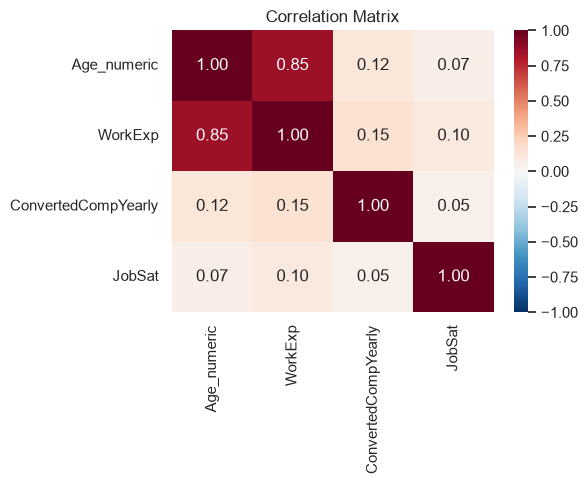

In [23]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

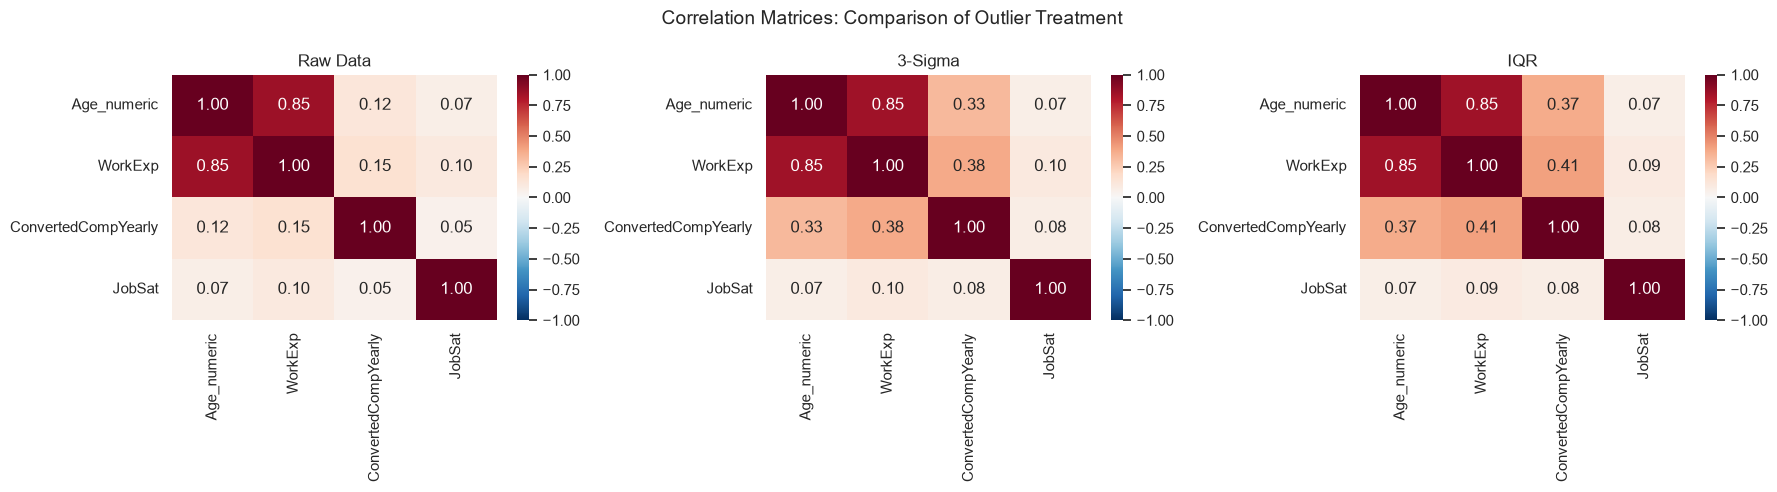

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw data
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    ax=axes[0]
)
axes[0].set_title("Raw Data")

# 3-Sigma
sns.heatmap(
    corr_matrix_3sigma,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title("3-Sigma")

# IQR
sns.heatmap(
    corr_matrix_iqr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    ax=axes[2]
)
axes[2].set_title("IQR")

fig.suptitle("Correlation Matrices: Comparison of Outlier Treatment", fontsize=14)
plt.tight_layout()
plt.show()

A few things stand out:
- **Age and WorkExp are strongly correlated (0.85)**, as expected — older respondents have had more time to accumulate professional experience. Neither one is redundant with the other for modeling, but this is worth knowing before using both as features.
- **WorkExp and ConvertedCompYearly have a moderate positive correlation (approximately 0.4 after IQR outlier treatment). This is the strongest relationship with compensation among the variables included in this matrix. It suggests that more experienced respondents tend to have higher annual compensation, although work experience alone does not explain the majority of the variation in salary.**
- **JobSat barely correlates with anything here** (all below 0.1) — consistent with the earlier finding that experience only weakly predicts satisfaction. Whatever drives job satisfaction in this dataset, it isn't captured well by age, experience, or pay alone.
- `CompTotal` is deliberately left out of this matrix — as established in the wrangling notebook, its extreme data-entry errors make any correlation involving it meaningless.

## Summary & next steps

Key findings from this notebook:
- Job satisfaction is generally high (median around 7–8) and only weakly tied to experience (Spearman ≈ 0.12)
- Remote work varies a lot by employment type — freelancers skew heavily remote (59%), full-time employees are more evenly split
- JavaScript/Python/SQL dominate both current use and future interest, but **Rust stands out as the language most wanted relative to how much it's currently used**
- Outlier detection methods disagree substantially on compensation (0.4% vs 4.2% flagged) — resolved by using domain judgment rather than a single automated cutoff, which is also what caught a $2M data-entry error from a single Gabon respondent
- Experience correlates moderately with compensation (0.41) but weakly with satisfaction (0.10); age matters mostly through its link to experience

These findings — especially the languages gap, the remote work split, and the compensation-by-country picture — are the ones carried forward into polished charts in the next notebook.

→ Continues in **04_Data_Visualization.ipynb**.